# APA - Lista de Problemas 2: Problema Individual 4

##  La dura vida del estudiante

In [44]:
# Descomentar para actualizar librerias
# Si se actualiza alguna libreria hay que reiniciar el notebook
# !pip install pandas --upgrade  --quiet
# !pip install numpy --upgrade  --quiet
# !pip install scipy --upgrade  --quiet
# !pip install statsmodels --upgrade  --quiet
# !pip install scikit-learn --upgrade  --quiet
!pip install missingno --upgrade  --quiet
!pip install apafib --upgrade --quiet

In [45]:
from IPython.core.interactiveshell import InteractiveShell
from sklearn.model_selection import train_test_split
from sklearn.model_selection import train_test_split,  KFold, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV, Lasso, LassoCV
from yellowbrick.regressor import residuals_plot, prediction_error
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
InteractiveShell.ast_node_interactivity = "all"

from time import time
from datetime import timedelta
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from pandas.plotting import scatter_matrix
init_time = time()

In [46]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.precision', 3)

## APARTADO A

### CARGA DE DATOS Y VISUALIZACIÓN

Cargamos los datos y separamos la variable objetivo (Stress Label) del conjunto de datos.

In [47]:
from apafib import load_stress

# Cargamos el DataFrame
data = load_stress()

# Separamos la variable objetivo del conjunto de datos
X = data.drop(columns=['Stress Label'])
y = data['Stress Label']

X.head()

,1. Age,2. Gender,5. Academic Year,6. Current CGPA,7. Did you receive a waiver or scholarship at your university?,"1. In a semester, how often have you felt upset due to something that happened in your academic affairs?","2. In a semester, how often you felt as if you were unable to control important things in your academic affairs?","3. In a semester, how often you felt nervous and stressed because of academic pressure?","4. In a semester, how often you felt as if you could not cope with all the mandatory academic activities? (e.g, assignments, quiz, exams)","5. In a semester, how often you felt confident about your ability to handle your academic / university problems?","6. In a semester, how often you felt as if things in your academic life is going on your way?","7. In a semester, how often are you able to control irritations in your academic / university affairs?","8. In a semester, how often you felt as if your academic performance was on top?","9. In a semester, how often you got angered due to bad performance or low grades that is beyond your control?","10. In a semester, how often you felt as if academic difficulties are piling up so high that you could not overcome them?"
0,18-22,Female,Fourth Year or Equivalent,2.50 - 2.99,No,2,2,3,2,2,2,2,2,2,2
1,18-22,Male,First Year or Equivalent,3.80 - 4.00,No,2,2,2,2,2,2,2,1,1,2
2,18-22,Male,First Year or Equivalent,3.00 - 3.39,No,3,2,2,3,3,2,3,2,2,1
3,18-22,Male,First Year or Equivalent,3.40 - 3.79,No,2,2,2,2,2,2,2,2,2,2
4,18-22,Male,First Year or Equivalent,3.40 - 3.79,No,2,2,2,2,2,2,2,2,2,2


In [48]:
X.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
1. Age,1977,5,18-22,1273,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2. Gender,1977,3,Male,1372,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5. Academic Year,1977,5,First Year or Equivalent,592,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6. Current CGPA,1977,6,3.00 - 3.39,572,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7. Did you receive a waiver or scholarship at your university?,1977,2,No,1571,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"1. In a semester, how often have you felt upset due to something that happened in your academic affairs?",1977.0,NaN,NaN,NaN,2.342,1.179,0.0,2.0,2.0,3.0,4.0
"2. In a semester, how often you felt as if you were unable to control important things in your academic affairs?",1977.0,NaN,NaN,NaN,2.32,1.155,0.0,2.0,2.0,3.0,4.0
"3. In a semester, how often you felt nervous and stressed because of academic pressure?",1977.0,NaN,NaN,NaN,2.706,1.135,0.0,2.0,3.0,4.0,4.0
"4. In a semester, how often you felt as if you could not cope with all the mandatory academic activities? (e.g, assignments, quiz, exams)",1977.0,NaN,NaN,NaN,2.361,1.224,0.0,2.0,2.0,3.0,4.0
"5. In a semester, how often you felt confident about your ability to handle your academic / university problems?",1977.0,NaN,NaN,NaN,1.825,1.085,0.0,1.0,2.0,2.0,4.0


Podemos mirar como se distribuyen los 3 valores de la variable objetivo en el conjunto de datos:

In [49]:
y.value_counts()

Stress Label
Moderate Stress          1316
High Perceived Stress     546
Low Stress                115
Name: count, dtype: int64

Vemos que más de la mitad de los estudiantes (un 66%) sufre un nivel de estrés medio, un 27% sufre un nivel de estrés alto y tan solo un 7% de los estudiantes sufre poco estrés.

Antes de hacer cualquier estudio de los datos miramos si hay valores perdidos:

In [50]:
X.isna().sum()

1. Age                                                                                                                                        0
2. Gender                                                                                                                                     0
5. Academic Year                                                                                                                              0
6. Current CGPA                                                                                                                               0
7. Did you receive a waiver or scholarship at your university?                                                                                0
1. In a semester, how often have you felt upset due to something that happened in your academic affairs?                                      0
2. In a semester, how often you felt as if you were unable to control important things in your academic affairs?                        

Vemos que no hay valores perdidos que tengamos que imputar.

### División entrenamiento y test
Particionamos los datos en conjunto de entrenamiento y conjunto de test (70% y 30% respectivamente). 

Tal y como se especifica en el enunciado usaremos una partición estratificada, para que haya aproximadamente la misma proporción de ejemplos de cada clase en cada partición y fijaremos el `random_state` con un valor distinto de cero para la reproducibilidad.

In [51]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

En el conjunto de datos que hemos visto antes, se puede observar que hay un conjunto de variables que son categóricas. A continuación, generaremos dos conjuntos de datos, uno en el que usemos la codificación numérica de las variables categóricas y otro en el que binarizemos las variables.

Primero identificamos las columnas categóricas que necesitan transformación mediante:

In [52]:
cat_cols = X_train.select_dtypes(include=['object', 'category']).columns
print(cat_cols)

Index(['1. Age', '2. Gender', '5. Academic Year', '6. Current CGPA',
       '7. Did you receive a waiver or scholarship at your university?'],
      dtype='object')


Para transformar el primer cojunto (codificación númerica) codificamos las categorías de estas variables en números secuenciales. Para ello definimos un diccionario para cada una de las 5 variables para mantener el orden lógico.

In [53]:
# Creamos copias para preservar los datos originales
X_train_num = X_train.copy()
X_test_num = X_test.copy()

age_map = {'18-22': 0, '23-26': 1, '27-30': 2}
gender_map = {'Female': 0, 'Male': 1, 'Prefer not to say': 2}
year_map = {'First Year or Equivalent': 0, 'Second Year or Equivalent': 1, 
            'Third Year or Equivalent': 2, 'Fourth Year or Equivalent': 3, 'Other': 4}
cgpa_map = {'2.50 - 2.99': 0, '3.00 - 3.39': 1, '3.40 - 3.79': 2, '3.80 - 4.00': 3, 'Other': 4}
scholarship_map = {'No': 0, 'Yes': 1} 

# Aplicamos el mapeo a los conjuntos
for df in [X_train_num, X_test_num]:
    df['1. Age'] = df['1. Age'].map(age_map)
    df['2. Gender'] = df['2. Gender'].map(gender_map)
    df['5. Academic Year'] = df['5. Academic Year'].map(year_map)
    df['6. Current CGPA'] = df['6. Current CGPA'].map(cgpa_map)
    df['7. Did you receive a waiver or scholarship at your university?'] = df['7. Did you receive a waiver or scholarship at your university?'].map(scholarship_map)

X_train_num.head()

,1. Age,2. Gender,5. Academic Year,6. Current CGPA,7. Did you receive a waiver or scholarship at your university?,"1. In a semester, how often have you felt upset due to something that happened in your academic affairs?","2. In a semester, how often you felt as if you were unable to control important things in your academic affairs?","3. In a semester, how often you felt nervous and stressed because of academic pressure?","4. In a semester, how often you felt as if you could not cope with all the mandatory academic activities? (e.g, assignments, quiz, exams)","5. In a semester, how often you felt confident about your ability to handle your academic / university problems?","6. In a semester, how often you felt as if things in your academic life is going on your way?","7. In a semester, how often are you able to control irritations in your academic / university affairs?","8. In a semester, how often you felt as if your academic performance was on top?","9. In a semester, how often you got angered due to bad performance or low grades that is beyond your control?","10. In a semester, how often you felt as if academic difficulties are piling up so high that you could not overcome them?"
1660,0.0,0,1,1.0,0,4,4,4,4,3,3,2,4,4,4
1513,0.0,0,2,3.0,0,4,3,4,4,3,3,3,3,3,4
709,1.0,1,3,1.0,0,2,2,2,1,1,0,2,1,2,2
1964,1.0,0,3,0.0,0,4,4,4,4,0,0,0,0,4,4
1016,0.0,1,0,4.0,0,2,2,3,2,2,2,3,2,0,1


Podemos observar que las 5 variables categóricas han sido transformadas correctamente.

A continuación generamos el segundo conjunto de datos con variables binarizadas aplicando One-Hot Encoding.

In [54]:
X_train_bin = pd.get_dummies(X_train, columns=cat_cols, drop_first=True, dtype=int)
X_test_bin = pd.get_dummies(X_test, columns=cat_cols, drop_first=True, dtype=int)

# Alinear las columnas del conjunto de test con las de entrenamiento.
X_train_bin, X_test_bin = X_train_bin.align(X_test_bin, join='left', axis=1, fill_value=0)
X_train_bin.head()

,"1. In a semester, how often have you felt upset due to something that happened in your academic affairs?","2. In a semester, how often you felt as if you were unable to control important things in your academic affairs?","3. In a semester, how often you felt nervous and stressed because of academic pressure?","4. In a semester, how often you felt as if you could not cope with all the mandatory academic activities? (e.g, assignments, quiz, exams)","5. In a semester, how often you felt confident about your ability to handle your academic / university problems?","6. In a semester, how often you felt as if things in your academic life is going on your way?","7. In a semester, how often are you able to control irritations in your academic / university affairs?","8. In a semester, how often you felt as if your academic performance was on top?","9. In a semester, how often you got angered due to bad performance or low grades that is beyond your control?","10. In a semester, how often you felt as if academic difficulties are piling up so high that you could not overcome them?",1. Age_23-26,1. Age_27-30,1. Age_Above 30,1. Age_Below 18,2. Gender_Male,2. Gender_Prefer not to say,5. Academic Year_Fourth Year or Equivalent,5. Academic Year_Other,5. Academic Year_Second Year or Equivalent,5. Academic Year_Third Year or Equivalent,6. Current CGPA_3.00 - 3.39,6. Current CGPA_3.40 - 3.79,6. Current CGPA_3.80 - 4.00,6. Current CGPA_Below 2.50,6. Current CGPA_Other,7. Did you receive a waiver or scholarship at your university?_Yes
1660,4,4,4,4,3,3,2,4,4,4,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0
1513,4,3,4,4,3,3,3,3,3,4,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0
709,2,2,2,1,1,0,2,1,2,2,1,0,0,0,1,0,1,0,0,0,1,0,0,0,0,0
1964,4,4,4,4,0,0,0,0,4,4,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
1016,2,2,3,2,2,2,3,2,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0


Las cinco variables categóricas han sido binrizadas correctamente.


Ahora podemos pasar a hacer una visualización mínima de las variables, empezando con un heatmap para ver las correlaciones entre ellas.

TODO:   - separar variable objetivo y resto en train?? (x, y)
        - codificar variable objetivo??
        - estudio minimo de los datos con train_X, train_X_num o train_X_bin
        - PCA y t-sne con train_X, train_X_num o train_X_bin

<Figure size 1400x1000 with 0 Axes>

<Axes: >

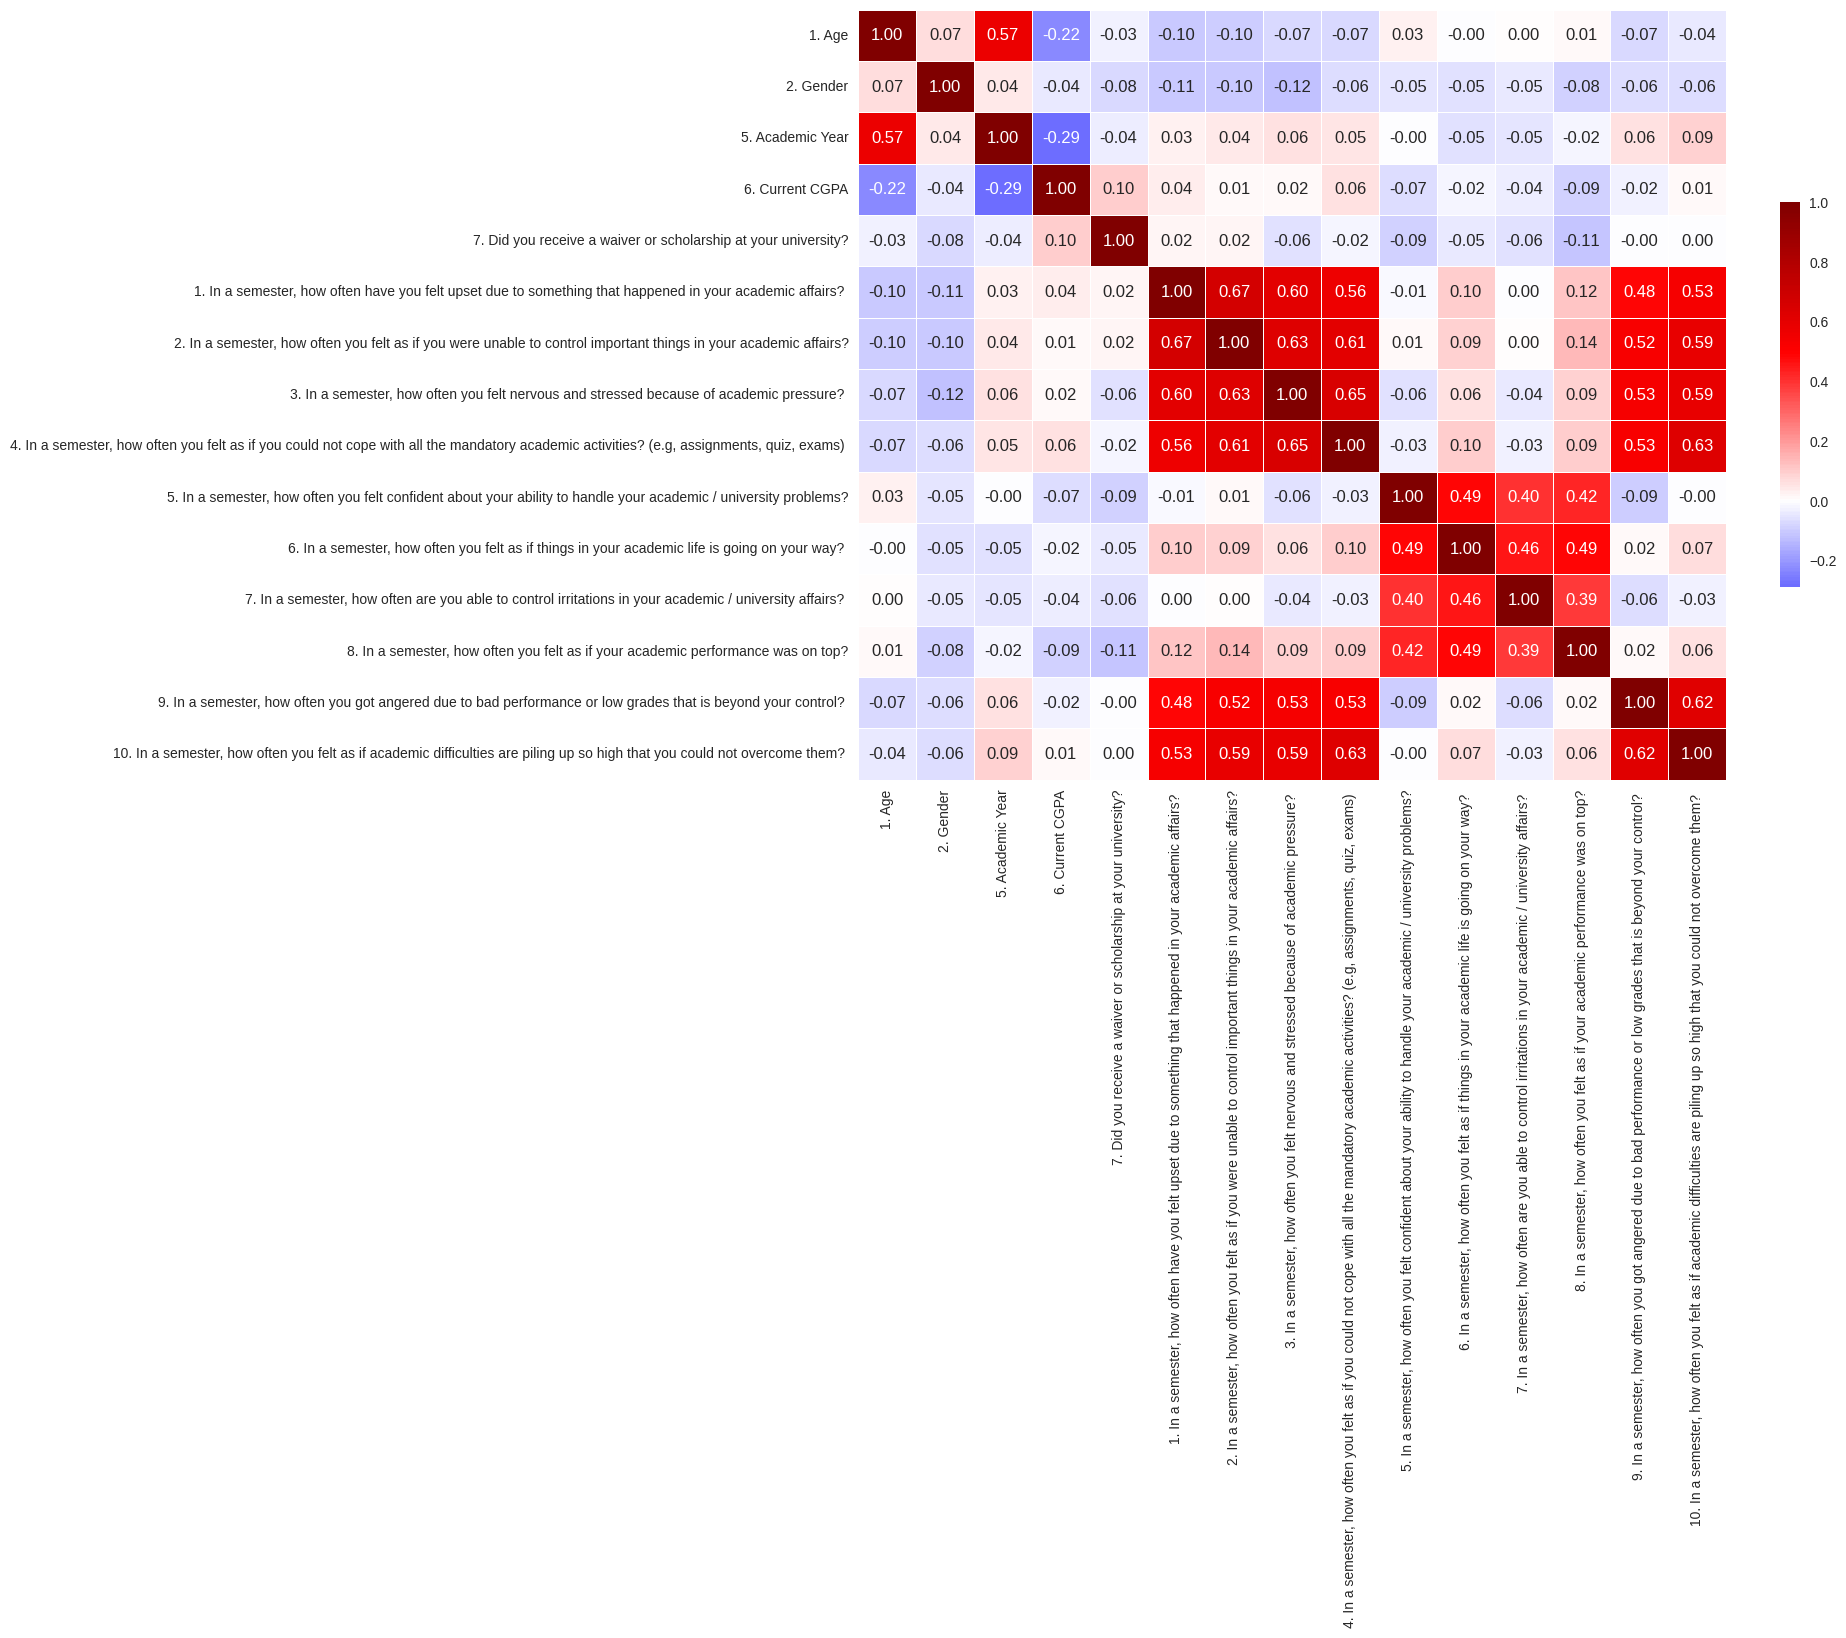

In [61]:
plt.figure(figsize=(14, 10))
corr_matrix = X_train_num.corr(numeric_only=True)
sns.heatmap(corr_matrix, annot=True, cmap='seismic', center=0, fmt=".2f",
            linewidths=.5, cbar_kws={"shrink": .5})
plt.show()

explicacion heatmap

array([[<Axes: title={'center': '1. Age'}>,
        <Axes: title={'center': '2. Gender'}>,
        <Axes: title={'center': '5. Academic Year'}>,
        <Axes: title={'center': '6. Current CGPA'}>],
       [<Axes: title={'center': '7. Did you receive a waiver or scholarship at your university?'}>,
        <Axes: title={'center': '1. In a semester, how often have you felt upset due to something that happened in your academic affairs? '}>,
        <Axes: title={'center': '2. In a semester, how often you felt as if you were unable to control important things in your academic affairs?'}>,
        <Axes: title={'center': '3. In a semester, how often you felt nervous and stressed because of academic pressure? '}>],
       [<Axes: title={'center': '4. In a semester, how often you felt as if you could not cope with all the mandatory academic activities? (e.g, assignments, quiz, exams) '}>,
        <Axes: title={'center': '5. In a semester, how often you felt confident about your ability to han

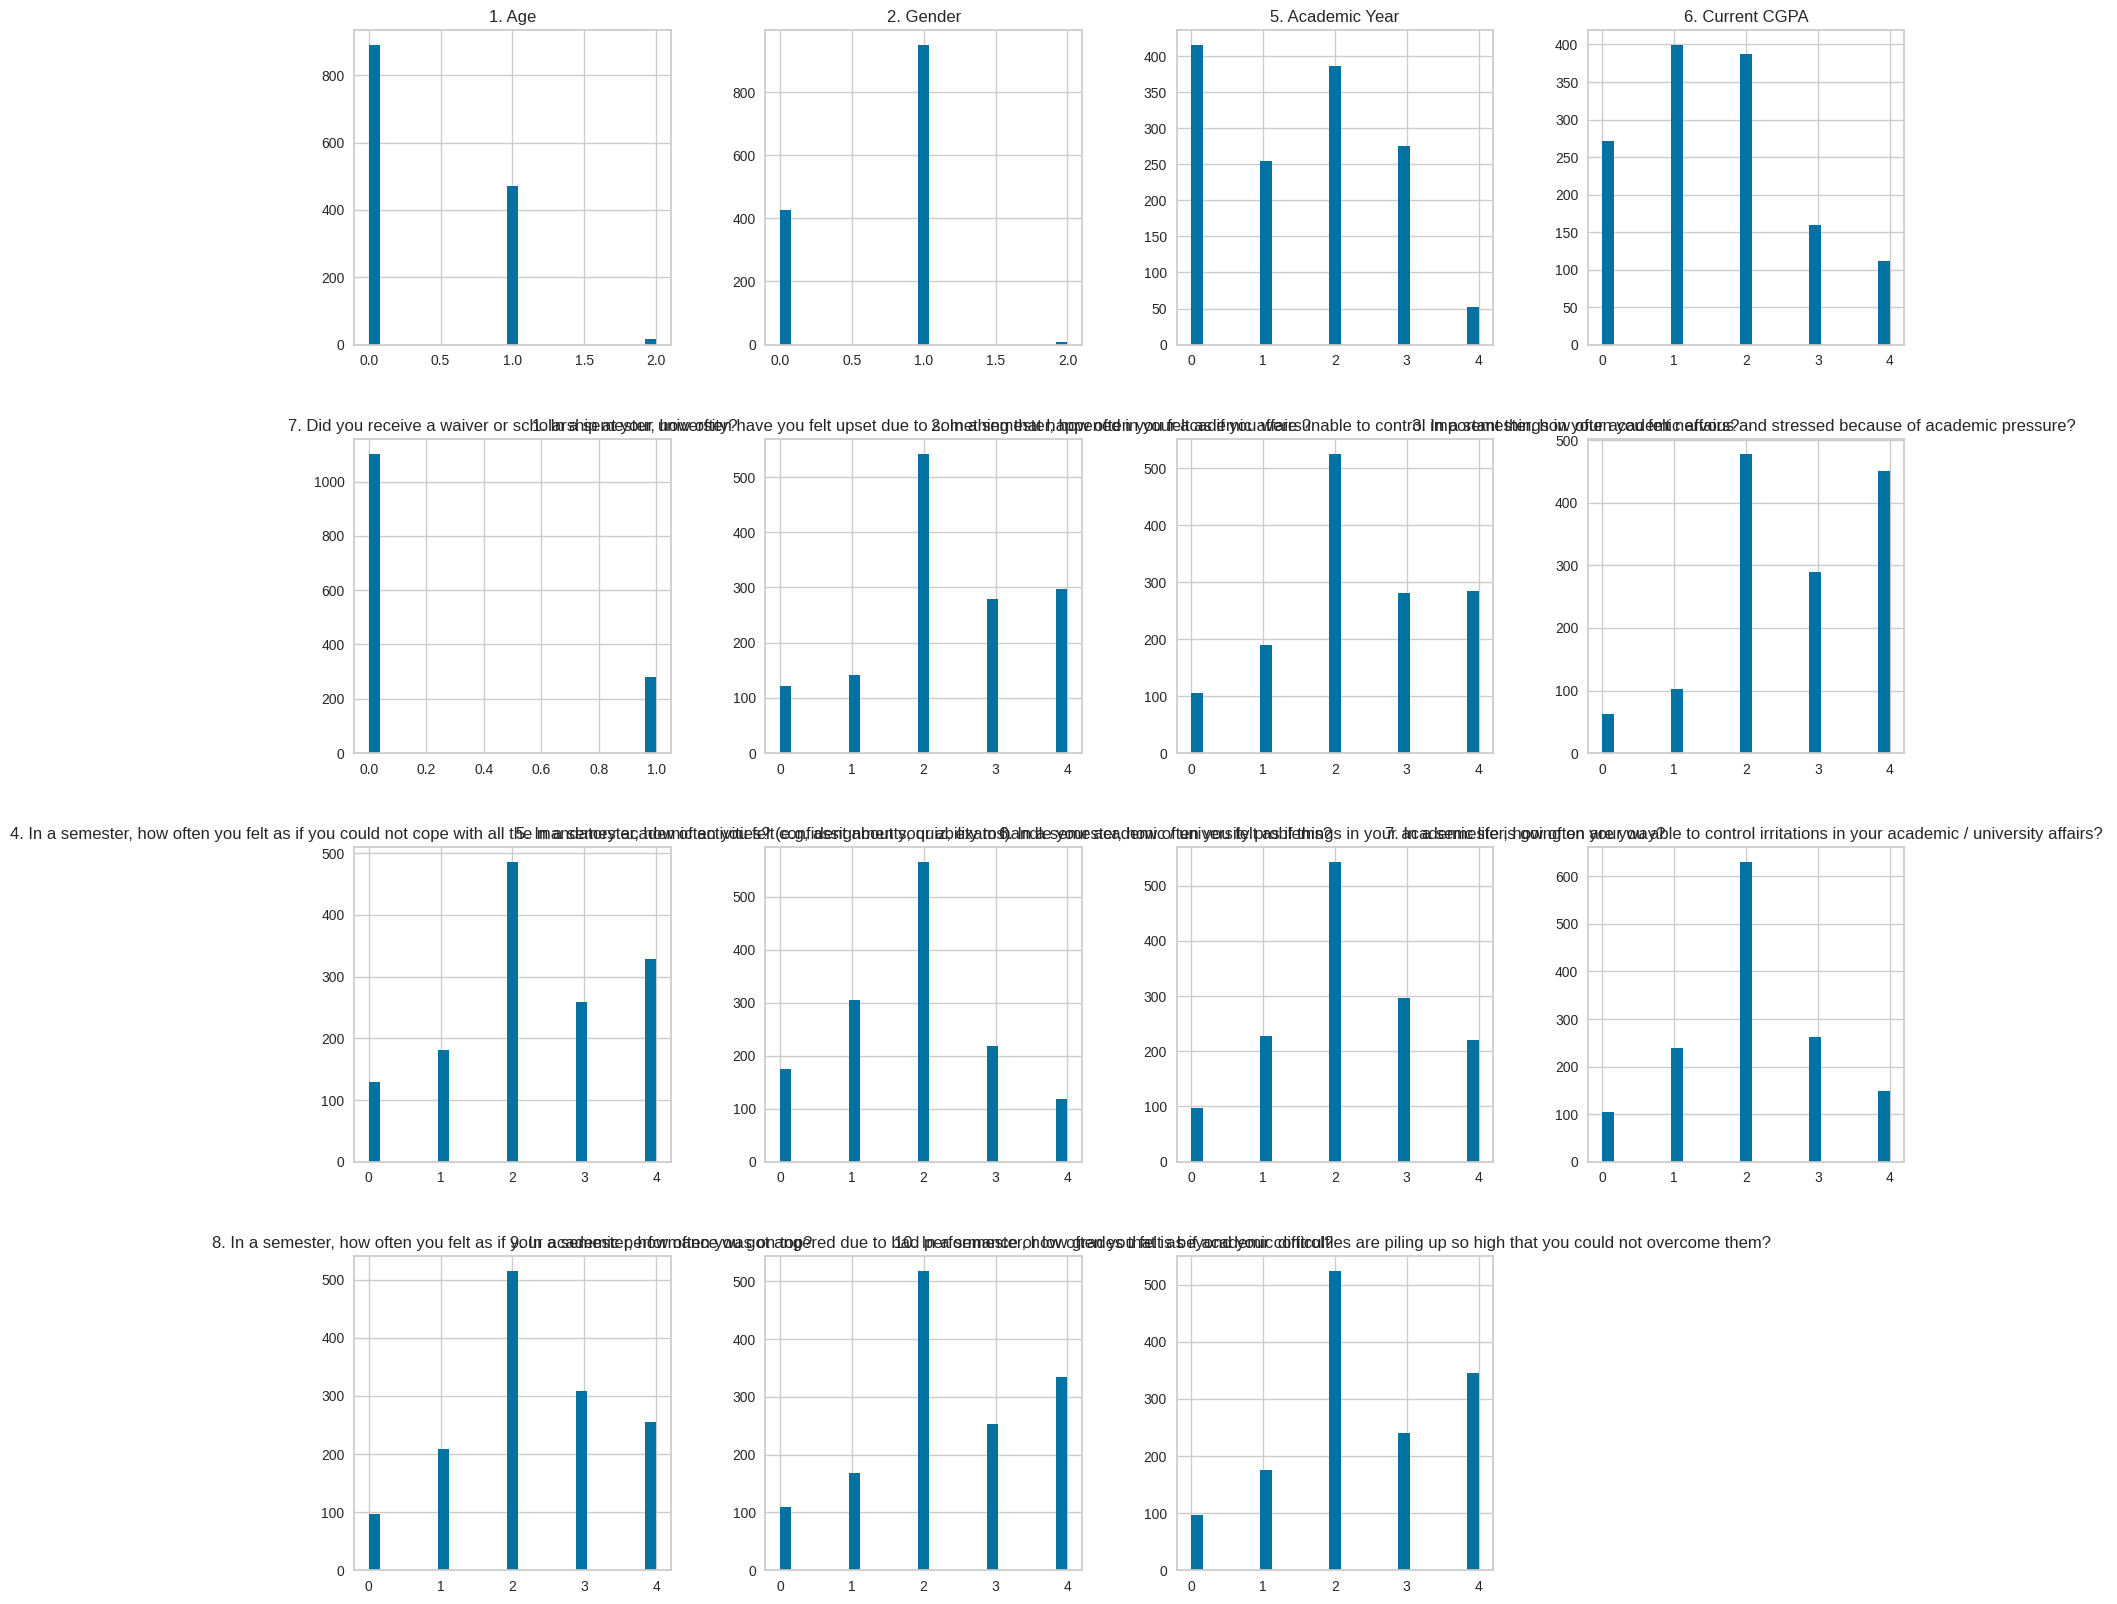

In [57]:
X_train_num.hist(bins=25, figsize=(20, 20));
plt.show()

### Estandarización

Estandarizamos los conjuntos X (media 0, desviación 1) para que PCA y t-sne no den más peso a las variables solo por tener valores más grandes (en Y no se hace porque es la variable objetivo).

In [62]:
scaler = StandardScaler()

# Ajustamos y transformamos X_train y X_test de X_train_num
X_train_num_scaled = pd.DataFrame(scaler.fit_transform(X_train_num), columns=X_train_num.columns)
X_test_num_scaled = pd.DataFrame(scaler.transform(X_test_num), columns=X_test_num.columns)

X_train_num_scaled.head()

,1. Age,2. Gender,5. Academic Year,6. Current CGPA,7. Did you receive a waiver or scholarship at your university?,"1. In a semester, how often have you felt upset due to something that happened in your academic affairs?","2. In a semester, how often you felt as if you were unable to control important things in your academic affairs?","3. In a semester, how often you felt nervous and stressed because of academic pressure?","4. In a semester, how often you felt as if you could not cope with all the mandatory academic activities? (e.g, assignments, quiz, exams)","5. In a semester, how often you felt confident about your ability to handle your academic / university problems?","6. In a semester, how often you felt as if things in your academic life is going on your way?","7. In a semester, how often are you able to control irritations in your academic / university affairs?","8. In a semester, how often you felt as if your academic performance was on top?","9. In a semester, how often you got angered due to bad performance or low grades that is beyond your control?","10. In a semester, how often you felt as if academic difficulties are piling up so high that you could not overcome them?"
0,-0.724,-1.479,-0.403,-0.490,-0.505,1.394,1.437,1.151,1.34,1.041,0.692,-0.080,1.491,1.345,1.340
1,-0.724,-1.479,0.421,1.204,-0.505,1.394,0.579,1.151,1.34,1.041,0.692,0.879,0.613,0.512,1.340
2,1.256,0.645,1.244,-0.490,-0.505,-0.301,-0.279,-0.614,-1.09,-0.778,-1.998,-0.080,-1.142,-0.321,-0.341
3,1.256,-1.479,1.244,-1.337,-0.505,1.394,1.437,1.151,1.34,-1.688,-1.998,-1.998,-2.020,1.345,1.340
4,-0.724,0.645,-1.227,2.051,-0.505,-0.301,-0.279,0.269,-0.28,0.132,-0.205,0.879,-0.265,-1.988,-1.182


In [64]:
X_train_num_scaled.describe().T

,count,mean,std,min,25%,50%,75%,max
1. Age,1376.0,1.446e-16,1.0,-0.724,-0.724,-0.724,1.256,3.236
2. Gender,1383.0,1.105e-16,1.0,-1.479,-1.479,0.645,0.645,2.770
5. Academic Year,1383.0,-3.083e-17,1.0,-1.227,-1.227,0.421,0.421,2.068
6. Current CGPA,1327.0,-2.276e-17,1.0,-1.337,-0.490,-0.490,0.357,2.051
7. Did you receive a waiver or scholarship at your university?,1383.0,4.110e-17,1.0,-0.505,-0.505,-0.505,-0.505,1.980
"1. In a semester, how often have you felt upset due to something that happened in your academic affairs?",1383.0,-1.875e-16,1.0,-1.995,-0.301,-0.301,0.546,1.394
"2. In a semester, how often you felt as if you were unable to control important things in your academic affairs?",1383.0,1.233e-16,1.0,-1.994,-0.279,-0.279,0.579,1.437
"3. In a semester, how often you felt nervous and stressed because of academic pressure?",1383.0,6.422e-17,1.0,-2.379,-0.614,0.269,1.151,1.151
"4. In a semester, how often you felt as if you could not cope with all the mandatory academic activities? (e.g, assignments, quiz, exams)",1383.0,1.850e-16,1.0,-1.900,-0.280,-0.280,0.530,1.340
"5. In a semester, how often you felt confident about your ability to handle your academic / university problems?",1383.0,-3.339e-17,1.0,-1.688,-0.778,0.132,0.132,1.951


In [63]:
# Ajustamos y transformamos X_train y X_test de X_train_bin
X_train_bin_scaled = pd.DataFrame(scaler.fit_transform(X_train_bin), columns=X_train_bin.columns)
X_test_bin_scaled = pd.DataFrame(scaler.transform(X_test_bin), columns=X_test_bin.columns)

X_train_bin_scaled.head()

,"1. In a semester, how often have you felt upset due to something that happened in your academic affairs?","2. In a semester, how often you felt as if you were unable to control important things in your academic affairs?","3. In a semester, how often you felt nervous and stressed because of academic pressure?","4. In a semester, how often you felt as if you could not cope with all the mandatory academic activities? (e.g, assignments, quiz, exams)","5. In a semester, how often you felt confident about your ability to handle your academic / university problems?","6. In a semester, how often you felt as if things in your academic life is going on your way?","7. In a semester, how often are you able to control irritations in your academic / university affairs?","8. In a semester, how often you felt as if your academic performance was on top?","9. In a semester, how often you got angered due to bad performance or low grades that is beyond your control?","10. In a semester, how often you felt as if academic difficulties are piling up so high that you could not overcome them?",1. Age_23-26,1. Age_27-30,1. Age_Above 30,1. Age_Below 18,2. Gender_Male,2. Gender_Prefer not to say,5. Academic Year_Fourth Year or Equivalent,5. Academic Year_Other,5. Academic Year_Second Year or Equivalent,5. Academic Year_Third Year or Equivalent,6. Current CGPA_3.00 - 3.39,6. Current CGPA_3.40 - 3.79,6. Current CGPA_3.80 - 4.00,6. Current CGPA_Below 2.50,6. Current CGPA_Other,7. Did you receive a waiver or scholarship at your university?_Yes
0,1.394,1.437,1.151,1.34,1.041,0.692,-0.080,1.491,1.345,1.340,-0.719,-0.108,-0.047,-0.054,-1.479,-0.071,-0.498,-0.198,2.103,-0.622,1.570,-0.623,-0.360,-0.205,-0.295,-0.505
1,1.394,0.579,1.151,1.34,1.041,0.692,0.879,0.613,0.512,1.340,-0.719,-0.108,-0.047,-0.054,-1.479,-0.071,-0.498,-0.198,-0.475,1.607,-0.637,-0.623,2.775,-0.205,-0.295,-0.505
2,-0.301,-0.279,-0.614,-1.09,-0.778,-1.998,-0.080,-1.142,-0.321,-0.341,1.392,-0.108,-0.047,-0.054,0.676,-0.071,2.007,-0.198,-0.475,-0.622,1.570,-0.623,-0.360,-0.205,-0.295,-0.505
3,1.394,1.437,1.151,1.34,-1.688,-1.998,-1.998,-2.020,1.345,1.340,1.392,-0.108,-0.047,-0.054,-1.479,-0.071,2.007,-0.198,-0.475,-0.622,-0.637,-0.623,-0.360,-0.205,-0.295,-0.505
4,-0.301,-0.279,0.269,-0.28,0.132,-0.205,0.879,-0.265,-1.988,-1.182,-0.719,-0.108,-0.047,-0.054,0.676,-0.071,-0.498,-0.198,-0.475,-0.622,-0.637,-0.623,-0.360,-0.205,3.385,-0.505


In [65]:
X_train_bin_scaled.describe().T

,count,mean,std,min,25%,50%,75%,max
"1. In a semester, how often have you felt upset due to something that happened in your academic affairs?",1383.0,-1.875e-16,1.0,-1.995,-0.301,-0.301,0.546,1.394
"2. In a semester, how often you felt as if you were unable to control important things in your academic affairs?",1383.0,1.233e-16,1.0,-1.994,-0.279,-0.279,0.579,1.437
"3. In a semester, how often you felt nervous and stressed because of academic pressure?",1383.0,6.422e-17,1.0,-2.379,-0.614,0.269,1.151,1.151
"4. In a semester, how often you felt as if you could not cope with all the mandatory academic activities? (e.g, assignments, quiz, exams)",1383.0,1.850e-16,1.0,-1.900,-0.280,-0.280,0.530,1.340
"5. In a semester, how often you felt confident about your ability to handle your academic / university problems?",1383.0,-3.339e-17,1.0,-1.688,-0.778,0.132,0.132,1.951
"6. In a semester, how often you felt as if things in your academic life is going on your way?",1383.0,-7.193e-17,1.0,-1.998,-0.205,-0.205,0.692,1.589
"7. In a semester, how often are you able to control irritations in your academic / university affairs?",1383.0,5.138e-18,1.0,-1.998,-0.080,-0.080,0.879,1.838
"8. In a semester, how often you felt as if your academic performance was on top?",1383.0,3.596e-17,1.0,-2.020,-0.265,-0.265,0.613,1.491
"9. In a semester, how often you got angered due to bad performance or low grades that is beyond your control?",1383.0,-9.248e-17,1.0,-1.988,-0.321,-0.321,0.512,1.345
"10. In a semester, how often you felt as if academic difficulties are piling up so high that you could not overcome them?",1383.0,1.053e-16,1.0,-2.022,-0.341,-0.341,0.500,1.340


## PCA

TODO : el X_train_num_scaled dice que tiene valores en NaN

Varianza explicada: [0.15455154 0.09417773 0.06808341 0.05412916 0.05196167 0.04826155
 0.04459367 0.04289334 0.04262318 0.04002969 0.03928996 0.03757799
 0.03583393 0.03452129 0.03080204 0.02391989 0.02320332 0.02241553
 0.02055463 0.01840323 0.01685296 0.01350323 0.01238932 0.01220423
 0.0092934  0.00793011]
Varianza acumulada: [0.15455154 0.24872927 0.31681268 0.37094184 0.42290351 0.47116506
 0.51575873 0.55865208 0.60127526 0.64130494 0.68059491 0.7181729
 0.75400683 0.78852812 0.81933016 0.84325005 0.86645337 0.88886891
 0.90942353 0.92782676 0.94467972 0.95818294 0.97057226 0.98277649
 0.99206989 1.        ]


Text(0, 0.5, 'Variancia explicada')

Text(0.5, 0, 'Componentes')

Text(0.5, 1.0, 'Porcentaje de variancia explicada por componente')

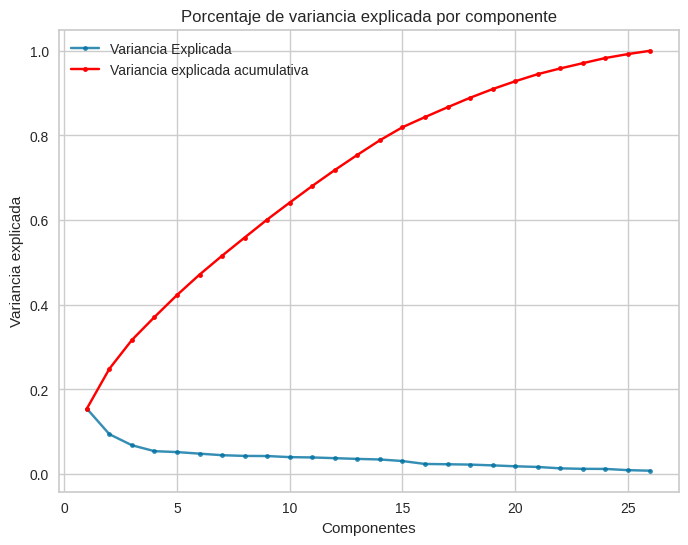

In [69]:
# Aplicar PCA a todos los datos estandarizados
pca_model = PCA().fit(X_train_bin_scaled)
print("Varianza explicada:", pca_model.explained_variance_ratio_)
print("Varianza acumulada:", pca_model.explained_variance_ratio_.cumsum())

# Varianza explicada
fig = plt.figure(figsize=(8,6))
plt.plot(range(1, len(pca_model.explained_variance_ratio_) + 1), pca_model.explained_variance_ratio_, alpha=0.8, marker='.', label="Variancia Explicada")
plt.ylabel('Variancia explicada')
plt.xlabel('Componentes')
plt.plot(range(1, len(pca_model.explained_variance_ratio_) + 1),
         np.cumsum(pca_model.explained_variance_ratio_),
         c='red', marker='.',
         label="Variancia explicada acumulativa")
plt.legend()
plt.title('Porcentaje de variancia explicada por componente')

14 variables para explicar el 80%

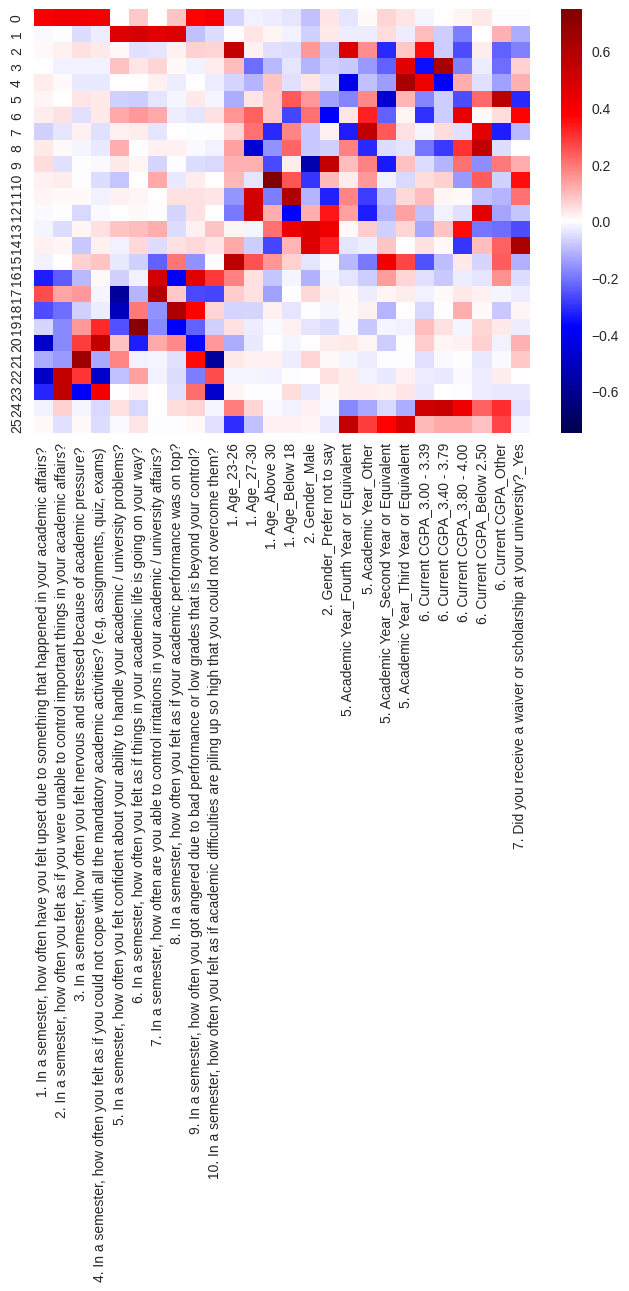

In [70]:
sns.heatmap(pca_model.components_, cmap='seismic', 
            xticklabels=list(X_train_bin_scaled.columns),
            vmin=-np.max(np.abs(pca_model.components_)),
            vmax=np.max(np.abs(pca_model.components_)),
            annot=False);

explicar

<Axes: xlabel='PC1', ylabel='PC2'>

Text(0.5, 1.0, 'PCA 2D - Distribución de Salud Financiera')

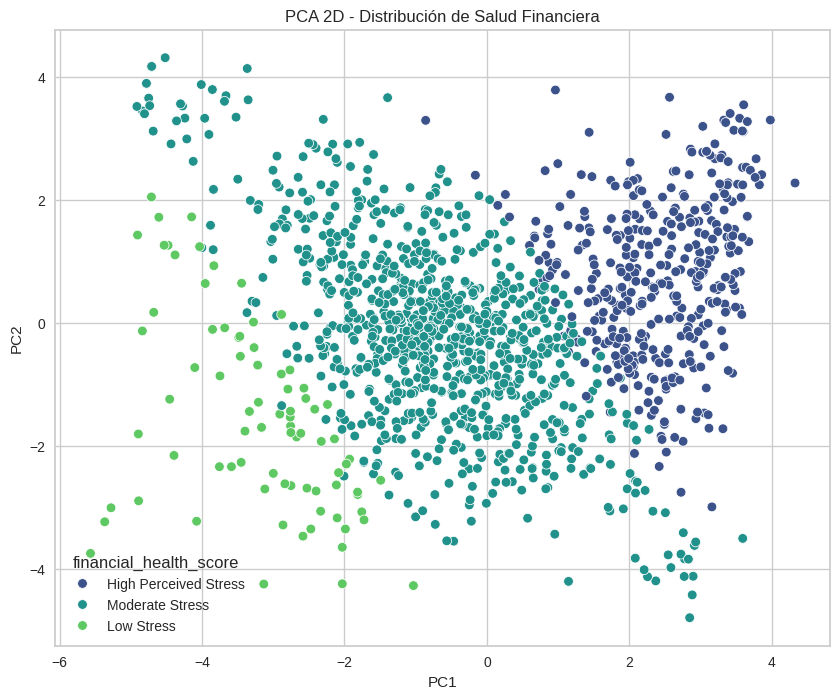

In [71]:
transformed_spending = pca_model.transform(X_train_bin_scaled)

df_plot = X_train_bin_scaled.copy()
df_plot['PC1'] = transformed_spending[:, 0]
df_plot['PC2'] = transformed_spending[:, 1]
df_plot['financial_health_score'] = y_train.values

fig = plt.figure(figsize=(10,8))
sns.scatterplot(x='PC1', y='PC2', hue='financial_health_score', data=df_plot, palette='viridis')
plt.title('PCA 2D - Distribución de Salud Financiera')